# Applying the pretrained iEEG HMM

This tutorial applies the pretrained hidden Markov model (HMM) to an intracranial
EEG recording and summarises the states it finds.

The model is a single-channel time-delay-embedded HMM (TDE-HMM) with 4 states,
trained on interictal stereo-EEG (SEEG) and electrocorticography (ECoG) from the
HUP epilepsy cohort
([OpenNeuro ds004100](https://openneuro.org/datasets/ds004100)) with
[osl-dynamics](https://github.com/OHBA-analysis/osl-dynamics). Each channel is
modelled independently, so the model can be applied to any number of channels
from any electrode layout. The states differ in their spectral content and are
numbered State 1-4 in order of decreasing low-frequency (1-4 Hz) power.

Steps:
1. Load the model.
2. Download an example recording (a subject held out from training).
3. Preprocess it the same way as the training data.
4. Infer state probabilities for every channel.
5. Visualise the state time courses and state spectra.
6. Compute summary statistics per channel.

To run this notebook, create the conda environment in the repository root:
```
conda env create -f environment.yml
conda activate ieeg-hmm
jupyter lab
```

In [1]:
import json
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

from osl_dynamics.analysis import post_hoc, spectral
from osl_dynamics.data import Data
from osl_dynamics.inference import modes
from osl_dynamics.models import load

STATE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

[08:38:42] Importing TensorFlow, this can take a while...


## 1. Load the model

The `model` directory contains the osl-dynamics model (`config.yml`,
`model.weights.h5`), the PCA projection applied to the time-delay embedded data
before it enters the HMM (`pca_components.npy`), and details of the training
data and model selection (`model_info.json`).

In [2]:
MODEL_DIR = Path("model")

model = load(MODEL_DIR)
pca_components = np.load(MODEL_DIR / "pca_components.npy")
info = json.loads((MODEL_DIR / "model_info.json").read_text())

n_states = info["n_states"]
STATE_NAMES = [f"State {k + 1}" for k in range(n_states)]

[08:38:50] Loading model: model


## 2. Download example data

We use one 5-minute interictal SEEG recording from subject HUP116, one of the
subjects held out from training. The recording (~16 MB) and its channel
information are downloaded from OpenNeuro.

In [3]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

url = "https://s3.amazonaws.com/openneuro.org/ds004100/sub-HUP116/ses-presurgery/ieeg"
stem = "sub-HUP116_ses-presurgery_task-interictal_acq-seeg_run-01"
for suffix in ("_ieeg.edf", "_channels.tsv"):
    path = DATA_DIR / f"{stem}{suffix}"
    if not path.exists():
        urllib.request.urlretrieve(f"{url}/{path.name}", path)

## 3. Preprocess

The model expects data preprocessed exactly as the training data:

| Step | Setting |
|---|---|
| Channels | good iEEG contacts only |
| Reference | bipolar (adjacent contacts on the same shaft, strip or grid row) |
| Notch filter | line frequency and harmonics |
| Band-pass filter | 0.1-45 Hz, FIR (zero-phase) |
| Sampling frequency | 100 Hz |
| Standardisation | each channel z-scored (done by `tde_pca` below) |

No bad-segment removal is needed: the model was trained on data containing
artefacts and epileptiform activity.

We load the recording and keep the contacts marked as good in the BIDS
`channels.tsv` file, which also marks the clinically identified seizure onset
zone (SOZ).

In [4]:
raw = mne.io.read_raw_edf(DATA_DIR / f"{stem}_ieeg.edf", preload=True, verbose="ERROR")
channels = pd.read_csv(DATA_DIR / f"{stem}_channels.tsv", sep="\t")

raw.pick(channels.loc[channels["status"] == "good", "name"].tolist())
soz_contacts = set(channels.loc[channels["status_description"].str.contains("soz", na=False), "name"])
print(f"{len(raw.ch_names)} good contacts at {raw.info['sfreq']:.0f} Hz, {raw.times[-1]:.0f} s")

50 good contacts at 500 Hz, 300 s


Bipolar re-reference: each contact is paired with the next one on the same shaft
(contact names are a shaft name followed by a number, e.g. `LA1` and `LA2`).
Adapt `bipolar_pairs` to your own naming scheme if needed.

In [5]:
def bipolar_pairs(ch_names):
    pairs = []
    for ch in ch_names:
        m = re.fullmatch(r"(.*?)(\d+)", ch)
        if m and f"{m[1]}{int(m[2]) + 1}" in ch_names:
            pairs.append((ch, f"{m[1]}{int(m[2]) + 1}"))
    return pairs

pairs = bipolar_pairs(raw.ch_names)
anodes, cathodes = [a for a, _ in pairs], [c for _, c in pairs]
raw.set_channel_types({ch: "seeg" for ch in raw.ch_names})
raw = mne.set_bipolar_reference(raw, anodes, cathodes, verbose="ERROR")
raw.pick([f"{a}-{c}" for a, c in zip(anodes, cathodes)])

# A bipolar channel is in the SOZ if either of its contacts is
is_soz = np.array([a in soz_contacts or c in soz_contacts for a, c in zip(anodes, cathodes)])
print(f"{len(raw.ch_names)} bipolar channels ({is_soz.sum()} in the SOZ)")

37 bipolar channels (6 in the SOZ)


/private/tmp/claude-501/-Users-cgohil-projects-ucl-hup/da1923c6-6468-4fa3-8663-b182d42a1688/scratchpad/env_test/lib/python3.12/site-packages/mne/_fiff/reference.py:713: RuntimeWarning: divide by zero encountered in matmul
  ref_data = multiplier @ inst._data
/private/tmp/claude-501/-Users-cgohil-projects-ucl-hup/da1923c6-6468-4fa3-8663-b182d42a1688/scratchpad/env_test/lib/python3.12/site-packages/mne/_fiff/reference.py:713: RuntimeWarning: overflow encountered in matmul
  ref_data = multiplier @ inst._data
/private/tmp/claude-501/-Users-cgohil-projects-ucl-hup/da1923c6-6468-4fa3-8663-b182d42a1688/scratchpad/env_test/lib/python3.12/site-packages/mne/_fiff/reference.py:713: RuntimeWarning: invalid value encountered in matmul
  ref_data = multiplier @ inst._data


Filter and resample (HUP data were recorded in the US, so the line frequency is 60 Hz).

In [6]:
LINE_FREQ = 60

raw.notch_filter(np.arange(LINE_FREQ, raw.info["sfreq"] / 2, LINE_FREQ), verbose="ERROR")
raw.filter(0.1, 45, fir_design="firwin", verbose="ERROR")
raw.resample(info["sampling_frequency_hz"], verbose="ERROR")
sfreq = raw.info["sfreq"]

## 4. Infer state probabilities

Each channel is passed to osl-dynamics as a separate time series. `tde_pca`
time-delay embeds and z-scores each channel, then projects it onto the model's
PCA components (these must be the ones in the model directory, not new ones);
the HMM then infers the probability of each state at each time point (`alpha`).

In [7]:
data = Data([ch[:, None] for ch in raw.get_data()])   # one (n_samples, 1) array per channel
data.prepare({
    "tde_pca": {"n_embeddings": info["n_embeddings"], "pca_components": pca_components},
    "standardize": {},
})
alpha = model.get_alpha(data)              # one (n_samples, n_states) array per channel

Time-delay embedding and batching into sequences removes a few samples from the
start and end of each channel, so `alpha` is slightly shorter than the input
(its first sample is input sample `n_embeddings // 2`). `trim_time_series`
returns the signal aligned sample-for-sample with `alpha`, and
`argmax_time_courses` gives the most probable state at each time point
(one-hot encoded).

In [8]:
signal = data.trim_time_series(sequence_length=info["sequence_length"], prepared=False)
stc = modes.argmax_time_courses(alpha)
print(f"{len(alpha)} channels, {alpha[0].shape[0]} samples, {n_states} states")

37 channels, 29800 samples, 4 states


## 5. Visualise the states

### State time course

A 10-second window from one seizure onset zone channel, centred on its
largest-amplitude event. The top panel shows the signal shaded by the most
probable state; the bottom panel shows the state probabilities.

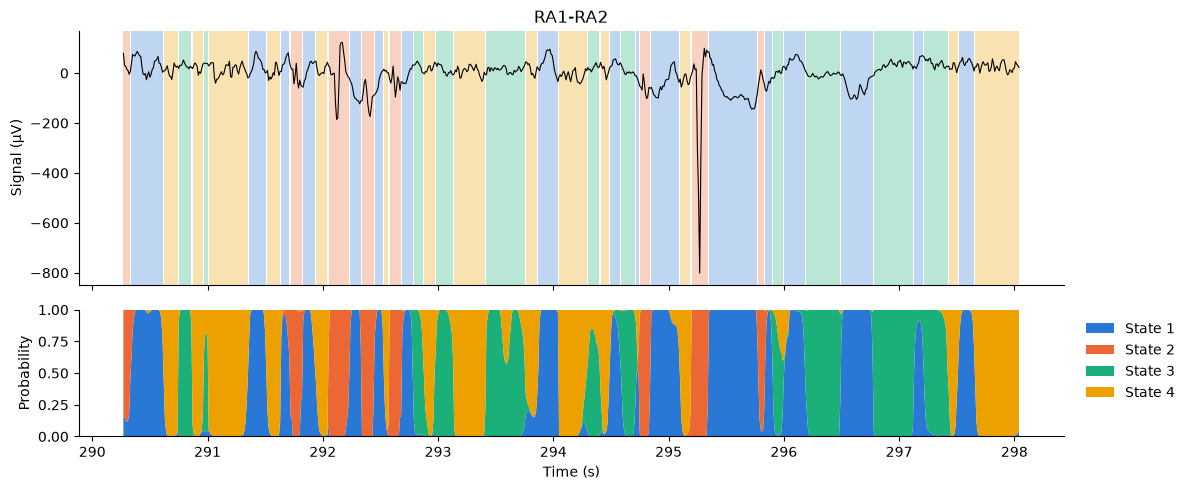

In [9]:
ch = np.flatnonzero(is_soz)[0]
y = signal[ch][:, 0] * 1e6                 # microvolts
peak = np.argmax(np.abs(y))
win = slice(max(peak - int(5 * sfreq), 0), peak + int(5 * sfreq))
t = (np.arange(len(y))[win] + info["n_embeddings"] // 2) / sfreq   # time in the recording
state = stc[ch][win].argmax(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True, height_ratios=[2, 1])
for k in range(n_states):
    ax1.fill_between(t, 0, 1, where=state == k, step="mid", transform=ax1.get_xaxis_transform(),
                     color=STATE_COLORS[k], alpha=0.3, lw=0)
ax1.plot(t, y[win], color="black", lw=0.8)
ax1.set(ylabel="Signal (µV)", title=raw.ch_names[ch])
ax2.stackplot(t, alpha[ch][win].T, colors=STATE_COLORS, labels=STATE_NAMES)
ax2.set(ylim=(0, 1), ylabel="Probability", xlabel="Time (s)")
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout()

### State spectra

The power spectrum of each state is estimated with a multitaper method weighted
by the state probabilities, then averaged over channels (`multitaper_spectra`
z-scores each channel first, so every channel contributes equally).

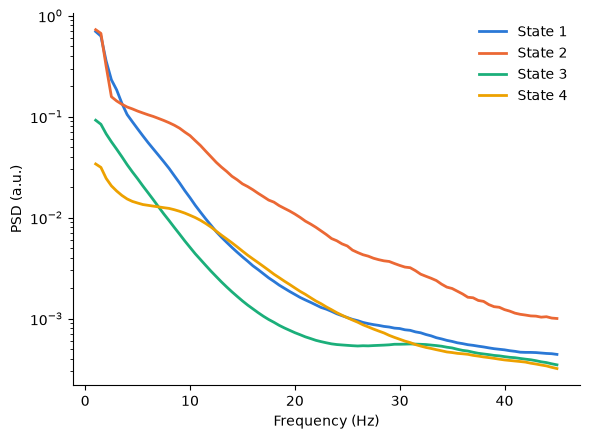

In [10]:
freqs, psd = spectral.multitaper_spectra(
    data=signal, alpha=alpha, sampling_frequency=sfreq, frequency_range=[1, 45], calc_coh=False,
)
psd = np.squeeze(psd)                      # (n_channels, n_states, n_freqs)

fig, ax = plt.subplots(figsize=(6, 4.5))
for k in range(n_states):
    ax.semilogy(freqs, psd[:, k].mean(axis=0), color=STATE_COLORS[k], lw=2, label=STATE_NAMES[k])
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (a.u.)")
ax.legend(frameon=False)
fig.tight_layout()

## 6. Summary statistics

For every channel and state: fractional occupancy (fraction of time in the
state), mean lifetime (average duration of a visit) and switching rate (visits
per second).

In [11]:
fo = post_hoc.fractional_occupancies(stc)                       # (n_channels, n_states)
lt = post_hoc.mean_lifetimes(stc, sampling_frequency=sfreq)     # seconds
sr = post_hoc.switching_rates(stc, sampling_frequency=sfreq)    # visits per second

pd.DataFrame({
    "Fractional occupancy": fo.mean(axis=0),
    "Mean lifetime (s)": np.nanmean(lt, axis=0),
    "Switching rate (/s)": sr.mean(axis=0),
}, index=STATE_NAMES).round(3)

,Fractional occupancy,Mean lifetime (s),Switching rate (/s)
State 1,0.291,0.182,1.624
State 2,0.151,0.140,1.115
State 3,0.165,0.128,1.100
State 4,0.393,0.213,1.869


These statistics can be compared across channels, e.g. the fractional occupancy
of each state in seizure onset zone channels versus the other channels of this
subject (one dot per channel).

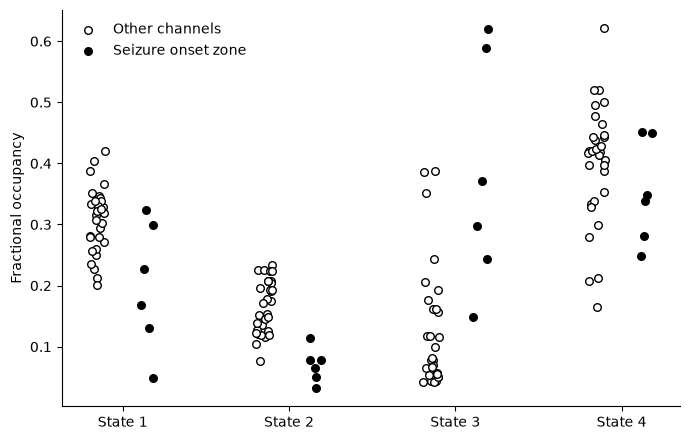

In [12]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 4.5))
for offset, mask, face, label in ((-0.15, ~is_soz, "white", "Other channels"),
                                  (0.15, is_soz, "black", "Seizure onset zone")):
    x_pos = np.arange(n_states) + offset + rng.uniform(-0.05, 0.05, (mask.sum(), n_states))
    ax.scatter(x_pos, fo[mask], s=30, facecolor=face, edgecolor="black", label=label)
ax.set_xticks(range(n_states), STATE_NAMES)
ax.set_ylabel("Fractional occupancy")
ax.legend(frameon=False)
fig.tight_layout()

## Using your own data

1. Keep only good iEEG contacts and bipolar re-reference them. For ECoG grids,
   pair neighbouring contacts within a row (e.g. drop pairs more than ~20 mm
   apart using the contact coordinates, which removes row ends such as
   `G8-G9` on an 8x8 grid).
2. Notch filter at your line frequency (50 or 60 Hz) and its harmonics,
   band-pass filter 0.1-45 Hz and resample to 100 Hz.
3. Prepare the data with the model's `pca_components` and call
   `model.get_alpha` (section 4).

Every array passed to `Data` is modelled independently, so channels from several
recordings (sessions or subjects) go into one `Data` object as one list. Keep a
matching list of labels to know which output belongs to which recording:

```python
arrays, labels = [], []
for session, raw in recordings.items():   # preprocessed mne.io.Raw per recording
    for ch, x in zip(raw.ch_names, raw.get_data()):
        arrays.append(x[:, None])
        labels.append((session, ch))

data = Data(arrays)
data.prepare({
    "tde_pca": {"n_embeddings": info["n_embeddings"], "pca_components": pca_components},
    "standardize": {},
})
alpha = model.get_alpha(data)              # alpha[i] belongs to labels[i]
```

Details of the training data, settings and model selection are in
`model/model_info.json`.